First 5 records:
   Study_Hours  Attendance_Percent  Previous_Marks  Sleep_Hours  \
0          3.6                  73              81          4.7   
1          7.7                  60              83          6.6   
2          6.1                  98              64          5.2   
3          5.2                  57              80          6.9   
4          2.1                  85              86          8.3   

   Assignment_Score  Final_Marks Performance  
0                94           92        High  
1                76          100        High  
2                67           98        High  
3                49           96        High  
4                78           86        High  

First 10 student records with clusters:
   Study_Hours  Attendance_Percent  Previous_Marks  Final_Marks  Cluster
0          3.6                  73              81           92        0
1          7.7                  60              83          100        0
2          6.1                  98    

C:\Users\Asus\.conda\envs\fairai\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


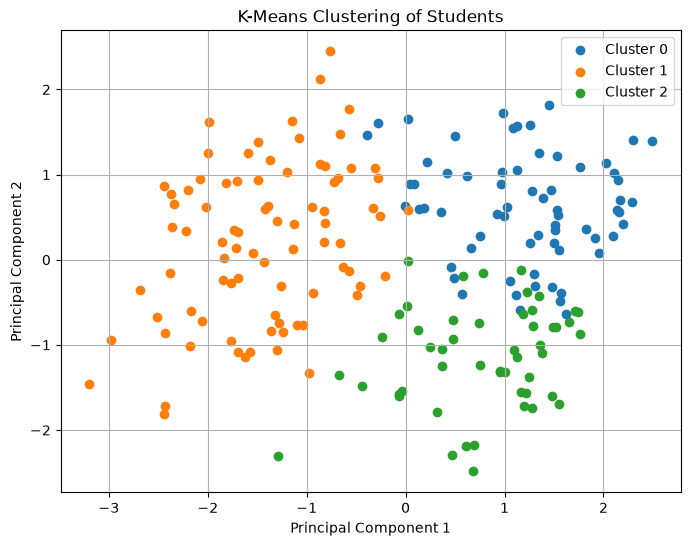


Average feature values for each cluster:
         Study_Hours  Attendance_Percent  Previous_Marks  Final_Marks
Cluster                                                              
0               5.54               82.76           81.06        96.86
1               2.40               74.07           62.75        69.76
2               6.14               72.90           51.59        95.02


In [2]:

# Assignment 10: K-Means Clustering

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Step 2: Load dataset
df = pd.read_csv("Student_Performance_Dataset.csv")

print("First 5 records:")
print(df.head())

# Step 3: Select numerical features
features = [
    "Study_Hours",
    "Attendance_Percent",
    "Previous_Marks",
    "Final_Marks"
]

X = df[features]

# Step 4: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 5: Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Step 6: Add cluster labels to dataset
df["Cluster"] = clusters

print("\nFirst 10 student records with clusters:")
print(df[features + ["Cluster"]].head(10))

print("\nNumber of students in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# Step 7: Reduce features to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Step 8: Plot clusters
plt.figure(figsize=(8, 6))

for cluster in sorted(df["Cluster"].unique()):
    mask = df["Cluster"] == cluster
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Students")
plt.legend()
plt.grid(True)
plt.show()

# Step 9: Display cluster averages
print("\nAverage feature values for each cluster:")
print(df.groupby("Cluster")[features].mean().round(2))


## Result
The K-Means Clustering algorithm was successfully implemented on the Student Performance Dataset. The students were divided into three clusters based on study hours, attendance percentage, previous marks, and final marks. A scatter plot was generated to visualize the clusters.

## Conclusion
K-Means grouped students with similar numerical characteristics without using predefined performance labels. Feature scaling was applied so that variables with different numerical ranges could contribute more fairly to distance calculations.